In [10]:
import polars as pl
import matplotlib.pyplot as plt
import contextily as ctx
import geopandas as gpd
from datetime import date

import yaml

with open("../config.budapest.yaml", "r") as fp:
    config = yaml.safe_load(fp)

In [2]:
PARTITION = 0  # between 0 and 255

In [12]:
stops = pl.read_parquet(
    f"{config['dirs']['output']}/{config['city']}/stops/{PARTITION:02x}.parquet"
)

In [15]:
stops.head(3)

device_id,stop_id,interval_start,interval_stop,interval_lenght,latitude_mean,longitude_mean,latitude_std,longitude_std,number_of_pings,place_label
i64,i32,"datetime[μs, Europe/Budapest]","datetime[μs, Europe/Budapest]",duration[μs],f64,f64,f64,f64,u32,i64
1,1,2024-10-02 07:24:06 CEST,2024-10-02 07:35:29 CEST,11m 23s,47.661166,19.076356,4.0,0.0,2,17
1,2,2024-10-05 11:06:43 CEST,2024-10-05 11:22:57 CEST,16m 14s,47.498402,19.0404,0.0,0.0,4,14
1,3,2024-10-05 17:49:22 CEST,2024-10-05 17:59:54 CEST,10m 32s,47.476742,19.075131,0.0,0.0,3,8


# descriptives

In [16]:
stop_pings = stops.filter(pl.col("stop_id") >= 0)

# stops per user
stops_per_user = stop_pings.group_by("device_id").agg(
    pl.col("stop_id").n_unique().alias("n_stops")
)
n_users_total = stops["device_id"].n_unique()
n_users_stopped = stops_per_user["device_id"].n_unique()

In [17]:
stops_per_user["n_stops"].clip(upper_bound=20).value_counts().sort(
    "count", descending=True
)

n_stops,count
u32,u32
20,2198
1,543
2,293
3,216
4,178
…,…
14,50
18,49
16,44


Users with >=1 stop:  4,478 / 4,478  (100.0%)

Stops per user:
shape: (9, 3)
┌────────────┬───────────┬─────────┐
│ statistic  ┆ device_id ┆ n_stops │
│ ---        ┆ ---       ┆ ---     │
│ str        ┆ i64       ┆ i64     │
╞════════════╪═══════════╪═════════╡
│ count      ┆ 4478      ┆ 4478    │
│ null_count ┆ 0         ┆ 0       │
│ mean       ┆ 3301      ┆ 88      │
│ std        ┆ 1907      ┆ 185     │
│ min        ┆ 1         ┆ 1       │
│ 25%        ┆ 1634      ┆ 4       │
│ 50%        ┆ 3314      ┆ 18      │
│ 75%        ┆ 4961      ┆ 80      │
│ max        ┆ 6584      ┆ 4002    │
└────────────┴───────────┴─────────┘


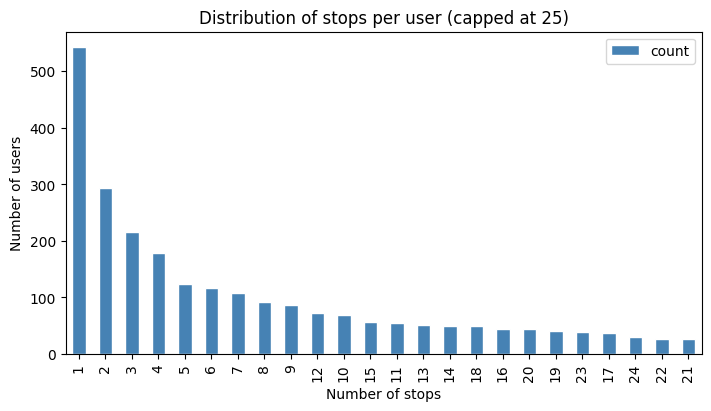

In [18]:
print(
    f"Users with >=1 stop:  {n_users_stopped:,} / {n_users_total:,}  ({n_users_stopped / n_users_total:.1%})"
)
print("\nStops per user:")
print(
    stops_per_user.describe().with_columns(
        pl.col.device_id.round().cast(pl.Int64),
        pl.col.n_stops.round().cast(pl.Int64),
    )
)

fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
# stops_per_user["n_stops"].clip(upper_bound=20).value_counts().sort(
#     "count", descending=True
# ).to_pandas().plot.bar(
#     ax=ax, x="n_stops", y="count", color="steelblue", edgecolor="white"
# )
stops_per_user.filter(pl.col.n_stops < 25)["n_stops"].value_counts().sort(
    "count", descending=True
).to_pandas().plot.bar(
    ax=ax, x="n_stops", y="count", color="steelblue", edgecolor="white"
)
ax.set_xlabel("Number of stops")
ax.set_ylabel("Number of users")
_ = ax.set_title("Distribution of stops per user (capped at 25)")

works on clustered pings

In [ ]:
example_device = 40  # old 16
# example_device = 290  # old 133

user_df = stops.filter(
    (pl.col.device_id == example_device)
    & (pl.col.timestamp.dt.date() == date(2025, 10, 6))
)

# build GeoDataFrame in Web Mercator for contextily
gdf = gpd.GeoDataFrame(
    user_df.to_pandas(),
    geometry=gpd.points_from_xy(user_df["longitude"], user_df["latitude"]),
    crs="EPSG:4326",
).to_crs("EPSG:3857")

fig, ax = plt.subplots(figsize=(12, 12), layout="constrained")

# moving pings
gdf[gdf["stop_id"] < 0].plot(
    ax=ax, color="grey", markersize=4, alpha=0.5, label="moving"
)

# stop pings — colour by stop cluster
stop_gdf = gdf[gdf["stop_id"] >= 0]
stop_gdf.plot(
    ax=ax,
    column="stop_id",
    cmap="tab10",
    markersize=30,
    alpha=0.85,
    legend=False,
    label="stop",
)

# annotate stop cluster centres
for label, grp in stop_gdf.groupby("stop_id"):
    cx, cy = grp.geometry.x.mean(), grp.geometry.y.mean()
    ax.annotate(
        str(label), (cx, cy), fontsize=7, ha="center", color="black", fontweight="bold"
    )

ctx.add_basemap(ax, source=ctx.providers.CartoDB.Positron, zoom="auto")

ax.set_axis_off()
_ = ax.set_title(f"Device {example_device} — all pings + stop clusters", pad=12)